# Lab12 — Dynamic Forecasting with ARIMA Models and Interventions
**ATSE · Final · 26 October 2026**  
**Miguel A. Arranz, PhD**

Developed from the executed v0.1 notebook. This notebook focuses on dynamic forecasting with **ARIMA-Tools v1.0.1**. Static forecasting and formal forecast evaluation are reserved for Lab13.

**Economic question.** How does accounting for extraordinary historical disturbances change our forecasts of U.S. industrial production, and what can conditional future interventions tell us?


## Learning objectives

After this lab, you should be able to produce multi-step dynamic forecasts, interpret forecast uncertainty, compare models with and without historical additive outliers (AOs), distinguish growth forecasts from level forecasts, and explain why conditional intervention scenarios are **not** forecasts of the occurrence of a future shock.

### Planned experiments

| Experiment | Estimation sample ends | Forecast horizon | Interpretation |
|---|---|---|---|
| A | 2017-12 | 24 months, 2018–2019 | Ordinary forecasting conditions |
| B | 2019-12 | 12 months, 2020 | Unexpected extraordinary disturbance |
| C | 2019-12 | 12 months, 2020 | Hypothetical future intervention, conditional scenario |

The models are AR(4) with a constant, with and without historical AOs in **1998-08, 2005-09 and 2008-09**. We retain the AR order to isolate the role of outlier treatment.

## 1. Environment and reproducibility

The installation cell targets **ARIMA-Tools v1.0.1** in a fresh Colab runtime. Skip it if this exact version and the other dependencies are already installed. All uncertainty below conditions on fitted parameters, known past innovations and deterministic future regressors. Parameter estimation and scenario uncertainty are excluded.


In [1]:
%pip -q install "ARIMA-Tools @ git+https://github.com/maarranz/ARIMA-Tools.git@v1.0.1" pandas_datareader matplotlib


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas_datareader import data as web
from statsmodels.tsa.arima.model import ARIMA
from scipy.stats import norm
from IPython.display import display
import arima_tools as at
import importlib.metadata as metadata

assert at.__version__ == "1.0.1", at.__version__
LEVELS = (0.50, 0.70, 0.80, 0.90, 0.95, 0.99)
print("Package versions:", {p: metadata.version(p) for p in
      ["ARIMA-Tools", "statsmodels", "numpy", "pandas", "scipy", "plotly"]})
print("Dynamic forecast function:", at.dynamic_forecast)
# Keep native interactive Plotly figures in Colab; retain native Plotly data for local validation.
import sys, os
LOCAL_VALIDATION = os.environ.get("LAB12_LOCAL_VALIDATION") == "1"
if LOCAL_VALIDATION:
    import plotly.io as pio
    pio.renderers.default = "plotly_mimetype"


Package versions: {'ARIMA-Tools': '1.0.1', 'statsmodels': '0.15.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'plotly': '5.24.1'}
Dynamic forecast function: <function dynamic_forecast at 0x7fe20e8a2520>


## 2. Data: U.S. industrial production

Use FRED series `INDPRO`. The growth rate is

\[g_t=100\bigl(\log(INDPRO_t)-\log(INDPRO_{t-1})\bigr).\]

We retrieve December 1989 to calculate January 1990 growth. **FRED data can be revised**: numerical results may differ from those saved in Lab11 if the vintage has changed. All comparisons within this notebook use the same downloaded series.

INDPRO observations: 373 | growth observations: 372


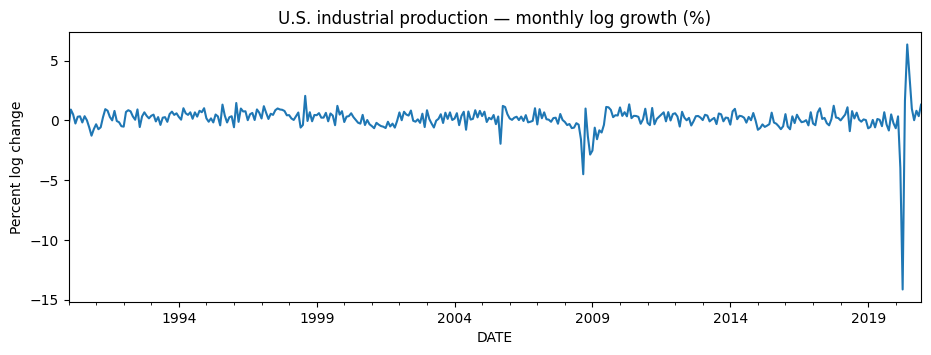

FRED retrieval date (UTC): 2026-10-26T16:02:17.677790+00:00


In [3]:
indpro = web.DataReader("INDPRO", "fred", start="1989-12-01", end="2020-12-31")["INDPRO"].dropna()
indpro.index = indpro.index.to_period("M").to_timestamp()
indpro = indpro.asfreq("MS")
assert indpro.notna().all(), "Missing INDPRO months require explicit treatment."
growth = (100 * np.log(indpro).diff()).loc["1990-01":"2020-12"].dropna()
assert growth.loc["1990-01":"2019-12"].shape[0] == 360
print("INDPRO observations:", len(indpro), "| growth observations:", len(growth))
fig, ax = plt.subplots(figsize=(11, 3.5))
growth.plot(ax=ax, title="U.S. industrial production — monthly log growth (%)")
ax.set_ylabel("Percent log change")
plt.show()
print("FRED retrieval date (UTC):", pd.Timestamp.now(tz="UTC").isoformat())


## 3. Models and historical additive outliers

An AO regressor equals 1 in the event month and 0 otherwise. In the forecast period, these **historical** AO regressors remain zero. This is not an assumption that no future shocks will occur; it simply means we do not assert any particular future AO.

In [4]:
EVENTS = ("1998-08", "2005-09", "2008-09")
AO_COLS = ("AO_1998_08", "AO_2005_09", "AO_2008_09")

def historical_aos(index):
    idx = pd.DatetimeIndex(index)
    x = pd.DataFrame(0.0, index=idx, columns=AO_COLS)
    for event, col in zip(EVENTS, AO_COLS):
        x.loc[idx.to_period("M") == pd.Period(event), col] = 1.0
    return x

def estimate_pair(end):
    y = growth.loc["1990-01":end]
    x = historical_aos(y.index)
    baseline = ARIMA(y, order=(4, 0, 0), trend="c").fit()
    adjusted = ARIMA(y, order=(4, 0, 0), trend="c", exog=x).fit()
    return y, x, baseline, adjusted

y17, x17, base17, ao17 = estimate_pair("2017-12")
y19, x19, base19, ao19 = estimate_pair("2019-12")
print(pd.DataFrame({
    "2017 baseline": [base17.aic, base17.bic],
    "2017 with AOs": [ao17.aic, ao17.bic],
    "2019 baseline": [base19.aic, base19.bic],
    "2019 with AOs": [ao19.aic, ao19.bic],
}, index=["AIC", "BIC"]).round(3))

     2017 baseline  2017 with AOs  2019 baseline  2019 with AOs
AIC        587.251        512.028        624.166        550.379
BIC        610.154        546.382        647.483        585.354


### API checkpoint

`at.dynamic_forecast(result, steps, level, *, exog=None)` returns columns `Forecast`, `FEV`, `SE`, `Lower`, and `Upper`, indexed by integer horizons **1,…,H**. We attach calendar dates only after checking the model's forecast index. Future historical AO columns must match the fitted column order and be zero throughout these forecast periods. ARIMA-Tools supplies marginal forecast-error variances, not the full joint covariance matrix.


In [5]:
import inspect
print(inspect.signature(at.dynamic_forecast))
print((inspect.getdoc(at.dynamic_forecast) or "No docstring")[:2500])

(result, steps=20, level=0.95, *, exog=None)
Produce recursive forecasts from the end of the observed sample.

Parameters
----------
result : statsmodels ARIMAResults
    Fitted Statsmodels ARIMA result. Supply future exog for every external
    regressor. Built-in trends are handled by Statsmodels.
steps : int, default 20
    Positive number of forecast horizons.
level : float, default 0.95
    Normal-theory prediction-interval coverage, strictly between 0 and 1.

exog : array-like or DataFrame, optional, keyword-only
    Future values for all external regressors, in fitted column order.
    DataFrame names and forecast indexes must match the model. Forecasts
    condition on these values; coefficient/date/decay uncertainty is excluded.

Returns
-------
pandas.DataFrame
    Index named 'Horizon', running from 1 through `steps`. Columns are
    Forecast, FEV, SE, Lower, and Upper. SE is sqrt(FEV); bounds use the
    requested normal quantile and the independently calculated FEV.

Notes

In [6]:
def dated_forecast(result, future, exog=None):
    expected = pd.date_range(result.model._index[-1] + pd.offsets.MonthBegin(1),
                             periods=len(future), freq="MS")
    pd.testing.assert_index_equal(pd.DatetimeIndex(future), expected)
    if exog is not None:
        pd.testing.assert_index_equal(exog.index, expected)
        assert list(exog.columns) == list(AO_COLS)
        assert result.model.exog_names == ["const", *AO_COLS]
        assert np.isfinite(exog.to_numpy()).all()
        assert (exog.to_numpy() == 0).all(), "Historical AOs must remain zero."
    raw = at.dynamic_forecast(result, steps=len(future), level=0.95, exog=exog)
    assert list(raw.columns) == ["Forecast", "FEV", "SE", "Lower", "Upper"]
    assert raw.index.equals(pd.RangeIndex(1, len(future) + 1, name="Horizon"))
    sm_forecast = result.forecast(len(future), exog=exog)
    pd.testing.assert_index_equal(sm_forecast.index, expected, check_names=False)
    np.testing.assert_allclose(raw.Forecast, sm_forecast, rtol=1e-12, atol=1e-12)
    return raw.set_axis(expected)


def growth_fan(result, future, exog, title):
    fig = at.plot_fan_chart(result, steps=len(future), levels=LEVELS, history=36, exog=exog)
    # Check every package band and its calendar coordinates before displaying.
    for trace in fig.data:
        if isinstance(trace.meta, dict) and "bound" in trace.meta:
            pd.testing.assert_index_equal(pd.DatetimeIndex(trace.x[1:]), future,
                                          check_names=False)
            table = at.dynamic_forecast(result, len(future), trace.meta["level"], exog=exog)
            np.testing.assert_allclose(np.asarray(trace.y[1:], float), table[trace.meta["bound"]])
    fig.add_scatter(x=future, y=growth.reindex(future), mode="lines", name="Realized (retrospective)",
                    line=dict(color="#b34236", width=2))
    fig.update_layout(title=title + "<br><sup>Central PIs: 50/70/80/90/95/99%</sup>")
    fig.update_yaxes(title_text="Monthly log growth (%)")
    fig.show()
    return fig


## 4. Experiment A — 24-month dynamic forecasts from December 2017

Both models are estimated using data available through 2017-12. Neither model is re-estimated during the 24-month forecast horizon. The AO model receives a future exogenous matrix of zeros, with exactly the same column order as its estimation regressors.

In [7]:
h_a = 24
future_a = pd.date_range("2018-01-01", periods=h_a, freq="MS")
future_aos_a = historical_aos(future_a)
forecast_a_base = dated_forecast(base17, future_a)
forecast_a_ao = dated_forecast(ao17, future_a, future_aos_a)
print("Baseline output type:", type(forecast_a_base))
display(forecast_a_base)
print("Historical-AO output type:", type(forecast_a_ao))
display(forecast_a_ao)
fan_a_base = growth_fan(base17, future_a, None, "A — 2018–2019: baseline AR(4)")
fan_a_ao = growth_fan(ao17, future_a, future_aos_a, "A — 2018–2019: historical-AO AR(4)")


Baseline output type: <class 'pandas.core.frame.DataFrame'>


,Forecast,FEV,SE,Lower,Upper
2018-01-01,0.388404,0.323948,0.569164,-0.727138,1.503945
2018-02-01,0.379057,0.328006,0.572718,-0.743449,1.501563
2018-03-01,0.233817,0.335678,0.579378,-0.901742,1.369377
2018-04-01,0.250082,0.355207,0.595993,-0.918042,1.418205
2018-05-01,0.261168,0.373503,0.611149,-0.936662,1.458999
2018-06-01,0.232309,0.377598,0.614490,-0.972070,1.436689
2018-07-01,0.210191,0.382555,0.618510,-1.002066,1.422448
2018-08-01,0.208669,0.387271,0.622311,-1.011037,1.428376
2018-09-01,0.201065,0.390133,0.624607,-1.023141,1.425272
2018-10-01,0.190548,0.391830,0.625963,-1.036317,1.417414


Historical-AO output type: <class 'pandas.core.frame.DataFrame'>


,Forecast,FEV,SE,Lower,Upper
2018-01-01,0.347065,0.254472,0.504453,-0.641644,1.335774
2018-02-01,0.307082,0.267172,0.516887,-0.705997,1.320161
2018-03-01,0.230507,0.275867,0.525230,-0.798925,1.259939
2018-04-01,0.229084,0.289801,0.538332,-0.826027,1.284196
2018-05-01,0.224410,0.299554,0.547315,-0.848307,1.297128
2018-06-01,0.207438,0.303450,0.550863,-0.872233,1.287109
2018-07-01,0.196488,0.306379,0.553515,-0.888383,1.281358
2018-08-01,0.190874,0.308521,0.555446,-0.897781,1.279529
2018-09-01,0.184999,0.309810,0.556606,-0.905929,1.275927
2018-10-01,0.179753,0.310605,0.557320,-0.912574,1.272080


**Discuss.** Do the forecast paths approach a constant? Does including historical AOs alter the estimated long-run mean or the rate of convergence? How does uncertainty change with horizon? Do not interpret differences as a causal effect of the historical events.

## 5. Experiment B — Forecasting the unforeseen 2020 collapse

Estimate through 2019-12 and forecast 2020 without using any information from 2020. Realizations are displayed **only after forecasts are computed**. Large forecast errors in 2020 illustrate a limitation of conditional time-series forecasts, not necessarily a programming or estimation error.

In [8]:
h_b = 12
future_b = pd.date_range("2020-01-01", periods=h_b, freq="MS")
future_aos_b = historical_aos(future_b)
forecast_b_base = dated_forecast(base19, future_b)
forecast_b_ao = dated_forecast(ao19, future_b, future_aos_b)
print("2020 baseline dynamic forecast:")
display(forecast_b_base)
print("2020 historical-AO dynamic forecast:")
display(forecast_b_ao)
print("2020 realized monthly growth (for retrospective inspection only):")
display(growth.loc["2020-01":"2020-12"].to_frame("realized_growth"))
fan_b_base = growth_fan(base19, future_b, None, "B — 2020: baseline AR(4)")
fan_b_ao = growth_fan(ao19, future_b, future_aos_b, "B — 2020: historical-AO AR(4)")


2020 baseline dynamic forecast:


,Forecast,FEV,SE,Lower,Upper
2020-01-01,-0.138385,0.320243,0.565900,-1.247530,0.970759
2020-02-01,-0.024963,0.323134,0.568449,-1.139102,1.089175
2020-03-01,0.058418,0.330913,0.575250,-1.069051,1.185887
2020-04-01,-0.015540,0.350511,0.592039,-1.175915,1.144836
2020-05-01,0.029792,0.367396,0.606132,-1.158205,1.217789
2020-06-01,0.059896,0.371107,0.609186,-1.134086,1.253878
2020-07-01,0.066790,0.375979,0.613172,-1.135004,1.268584
2020-08-01,0.069760,0.380432,0.616792,-1.139130,1.278650
2020-09-01,0.085001,0.383035,0.618898,-1.128018,1.298019
2020-10-01,0.093283,0.384619,0.620177,-1.122241,1.308807


2020 historical-AO dynamic forecast:


,Forecast,FEV,SE,Lower,Upper
2020-01-01,-0.087394,0.256666,0.506623,-1.080356,0.905568
2020-02-01,0.024163,0.266194,0.515940,-0.987061,1.035388
2020-03-01,0.052185,0.274861,0.524272,-0.975370,1.079739
2020-04-01,0.038090,0.289249,0.537818,-1.016015,1.092194
2020-05-01,0.070878,0.298426,0.546284,-0.999819,1.141574
2020-06-01,0.089258,0.302060,0.549600,-0.987938,1.166454
2020-07-01,0.097498,0.304994,0.552263,-0.984917,1.179913
2020-08-01,0.106284,0.307095,0.554162,-0.979852,1.192421
2020-09-01,0.115094,0.308333,0.555277,-0.973229,1.203417
2020-10-01,0.121036,0.309110,0.555977,-0.968659,1.210730


2020 realized monthly growth (for retrospective inspection only):


,realized_growth
DATE,
2020-01-01,-0.657514
2020-02-01,0.335660
2020-03-01,-3.990543
2020-04-01,-14.142248
2020-05-01,1.640291
2020-06-01,6.347249
2020-07-01,3.678711
2020-08-01,0.973196
2020-09-01,0.012505


## 6. Forecasting the level of industrial production

For the stationary ARMA model of monthly log growth, let $\psi_0=1,\psi_1,\ldots$ be its MA representation and $\sigma^2$ the innovation variance. The horizon-$h$ forecast error is $e_h=\sum_{k=1}^h\psi_{h-k}\epsilon_{T+k}$. Construct the lower-triangular matrix $G_{hk}=\psi_{h-k}$ for $k\leq h$. Then

\[
\Sigma=\operatorname{Cov}(e_1,\ldots,e_H)=\sigma^2 GG',\qquad
V_h=\operatorname{Var}\left(\sum_{j=1}^h e_j\right)
=\left[C\Sigma C'\right]_{hh},
\]

where $C$ is lower triangular with ones. Summing marginal growth variances omits cross-horizon covariances and is generally incorrect. The code derives $\psi$ recursively from the fitted reduced AR and MA polynomials and verifies $\operatorname{diag}(\Sigma)$ against ARIMA-Tools.

Writing $m_h=\log I_T+\sum_{j=1}^h\hat g_{T+j|T}/100$ and $v_h=V_h/100^2$, the conditional **median** index is $\exp(m_h)$; the conditional **mean**, under Gaussian forecast errors, is $\exp(m_h+v_h/2)$. Central level intervals are $\exp(m_h\pm z_{(1+p)/2}\sqrt{v_h})$, centered in log space on $m_h$, not on the mean level. These are pointwise intervals, not simultaneous path bands.


A baseline — index forecasts (median, mean and 95% bounds):


,Median,Mean,Lower_95%,Upper_95%
2018-01-01,101.8593,101.8609,100.7293,103.0019
2018-02-01,102.2461,102.2498,100.5545,103.9661
2018-03-01,102.4854,102.4918,100.2698,104.7501
2018-04-01,102.7421,102.7523,99.9448,105.6176
2018-05-01,103.0107,103.0261,99.5869,106.5523
2018-06-01,103.2503,103.2715,99.2344,107.4287
2018-07-01,103.4676,103.4954,98.8719,108.2769
2018-08-01,103.6837,103.7190,98.5139,109.1248
2018-09-01,103.8924,103.9359,98.1627,109.9565
2018-10-01,104.0905,104.1429,97.8198,110.7633


A historical AOs — index forecasts (median, mean and 95% bounds):


,Median,Mean,Lower_95%,Upper_95%
2018-01-01,101.8172,101.8185,100.8154,102.8288
2018-02-01,102.1303,102.1335,100.5472,103.7384
2018-03-01,102.3660,102.3718,100.2461,104.5307
2018-04-01,102.6008,102.6101,99.9188,105.3547
2018-05-01,102.8313,102.8451,99.5806,106.1880
2018-06-01,103.0448,103.0637,99.2498,106.9849
2018-07-01,103.2475,103.2720,98.9279,107.7557
2018-08-01,103.4447,103.4755,98.6184,108.5073
2018-09-01,103.6363,103.6737,98.3230,109.2367
2018-10-01,103.8227,103.8671,98.0424,109.9439


B baseline — index forecasts (median, mean and 95% bounds):


,Median,Mean,Lower_95%,Upper_95%
2020-01-01,101.5597,101.5613,100.4394,102.6924
2020-02-01,101.5343,101.5379,99.8780,103.2181
2020-03-01,101.5936,101.5998,99.4309,103.8034
2020-04-01,101.5779,101.5876,98.8534,104.3774
2020-05-01,101.6081,101.6228,98.2839,105.0448
2020-06-01,101.6690,101.6891,97.7804,105.7123
2020-07-01,101.7369,101.7633,97.2950,106.3816
2020-08-01,101.8079,101.8414,96.8200,107.0528
2020-09-01,101.8945,101.9356,96.3753,107.7298
2020-10-01,101.9896,102.0389,95.9574,108.4010


B historical AOs — index forecasts (median, mean and 95% bounds):


,Median,Mean,Lower_95%,Upper_95%
2020-01-01,101.6115,101.6128,100.6075,102.6254
2020-02-01,101.6360,101.6392,100.0773,103.2190
2020-03-01,101.6891,101.6947,99.6126,103.8088
2020-04-01,101.7278,101.7368,99.1051,104.4199
2020-05-01,101.7999,101.8132,98.6272,105.0747
2020-06-01,101.8908,101.9090,98.1932,105.7278
2020-07-01,101.9902,102.0138,97.7860,106.3752
2020-08-01,102.0987,102.1281,97.4053,107.0183
2020-09-01,102.2163,102.2520,97.0530,107.6542
2020-10-01,102.3401,102.3825,96.7263,108.2797


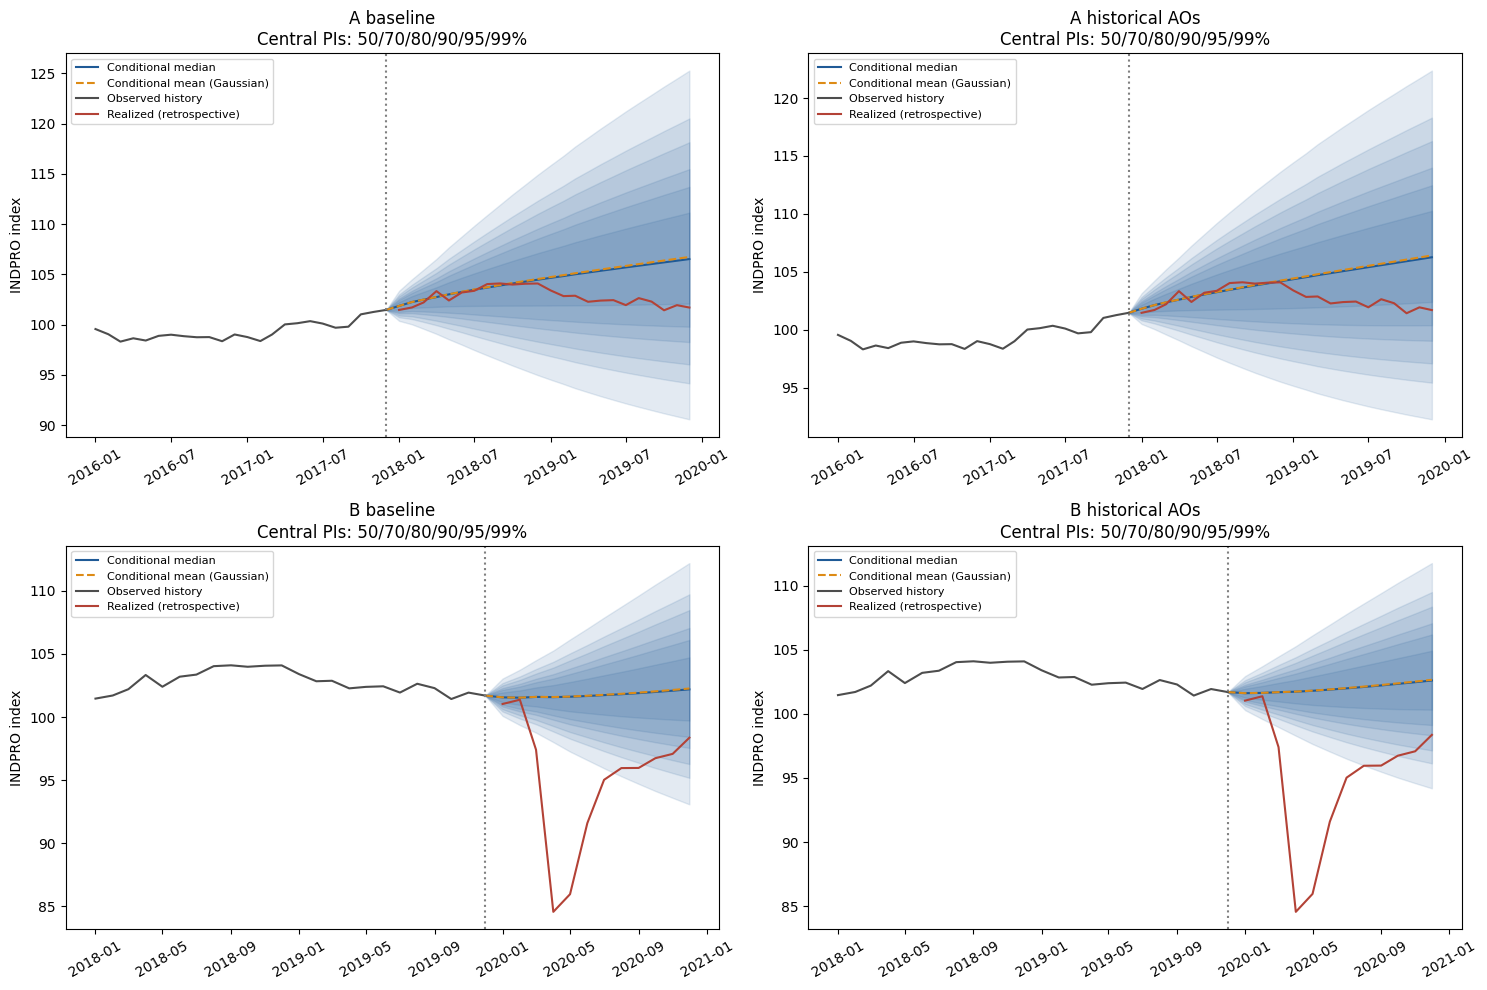

,Horizon,max_abs_FEV_difference,full_cumulative_variance,sum_marginal_variances_INCORRECT,min_covariance_eigenvalue,converged
Model,,,,,,
A baseline,24,5.551115e-17,39.632735,9.190127,0.189253,True
A historical AOs,24,5.551115e-17,30.033584,7.292402,0.184766,True
B baseline,12,1.110223e-16,13.155618,4.360361,0.194701,True
B historical AOs,12,5.551115e-17,11.016828,3.536604,0.185272,True


In [9]:
def arma_joint_covariance(result, horizon):
    assert result.model.order[1] == 0 and result.model.seasonal_order[1] == 0
    ar = np.asarray(result.polynomial_reduced_ar, float)
    ma = np.asarray(result.polynomial_reduced_ma, float)
    assert ar[0] == 1 and ma[0] == 1
    psi = np.zeros(horizon)
    for j in range(horizon):
        psi[j] = (ma[j] if j < len(ma) else 0.0) - sum(
            ar[k] * psi[j-k] for k in range(1, min(j, len(ar)-1)+1))
    sigma2 = (float(result.scale) if result.model.concentrate_scale else
              float(np.asarray(result.params)[result.param_names.index("sigma2")]))
    G = np.zeros((horizon, horizon))
    for h in range(horizon):
        G[h, :h+1] = psi[h::-1]
    covariance = sigma2 * G @ G.T
    package_variance = at.forecast_error_variance(result, steps=horizon)
    np.testing.assert_allclose(np.diag(covariance), package_variance, rtol=1e-11, atol=1e-12)
    np.testing.assert_allclose(covariance, covariance.T, atol=1e-12)
    assert np.linalg.eigvalsh(covariance).min() > -1e-10
    C = np.tril(np.ones((horizon, horizon)))
    cumulative_variance = np.diag(C @ covariance @ C.T)
    # Independent expression: cumulative responses to each future innovation.
    np.testing.assert_allclose(cumulative_variance,
                               sigma2 * np.cumsum(np.cumsum(psi)**2), rtol=1e-11)
    return covariance, cumulative_variance


def level_forecast(result, dated, origin_level):
    covariance, cumulative_variance = arma_joint_covariance(result, len(dated))
    log_center = np.log(origin_level) + dated.Forecast.cumsum().to_numpy()/100
    log_variance = cumulative_variance/10000
    table = pd.DataFrame({"log_center": log_center, "log_variance": log_variance,
                          "Median": np.exp(log_center),
                          "Mean": np.exp(log_center + log_variance/2)}, index=dated.index)
    for coverage in LEVELS:
        z = norm.ppf((1+coverage)/2)
        table[f"Lower_{coverage:.0%}"] = np.exp(log_center-z*np.sqrt(log_variance))
        table[f"Upper_{coverage:.0%}"] = np.exp(log_center+z*np.sqrt(log_variance))
    assert np.isfinite(table.to_numpy()).all()
    assert (table.Mean >= table.Median).all()
    return table, covariance, cumulative_variance


def level_fan(ax, table, title, origin, origin_level):
    x = pd.DatetimeIndex([origin, *table.index])
    for coverage in reversed(LEVELS):
        ax.fill_between(x, np.r_[origin_level, table[f"Lower_{coverage:.0%}"]],
                        np.r_[origin_level, table[f"Upper_{coverage:.0%}"]],
                        color="#1f5a96", alpha=0.12)
    ax.plot(x, np.r_[origin_level, table.Median], label="Conditional median", color="#1f5a96")
    ax.plot(x, np.r_[origin_level, table.Mean], label="Conditional mean (Gaussian)",
            color="#dd8b15", linestyle="--")
    history = indpro.loc[:origin].tail(24)
    ax.plot(history.index, history, color="0.3", label="Observed history")
    ax.plot(table.index, indpro.reindex(table.index), color="#b34236", label="Realized (retrospective)")
    ax.axvline(origin, color="0.5", linestyle=":")
    ax.set(title=title + "\nCentral PIs: 50/70/80/90/95/99%", ylabel="INDPRO index")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelrotation=30)


experiments = {
    "A baseline": (base17, forecast_a_base), "A historical AOs": (ao17, forecast_a_ao),
    "B baseline": (base19, forecast_b_base), "B historical AOs": (ao19, forecast_b_ao),
}
level_tables, covariance_checks = {}, []
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (label, (result, dated)) in zip(axes.flat, experiments.items()):
    origin = result.model._index[-1]
    table, covariance, cumulative = level_forecast(result, dated, float(indpro.loc[origin]))
    level_tables[label] = table
    level_fan(ax, table, label, origin, float(indpro.loc[origin]))
    h = len(dated)
    covariance_checks.append({
        "Model": label, "Horizon": h,
        "max_abs_FEV_difference": np.max(np.abs(np.diag(covariance)-dated.FEV)),
        "full_cumulative_variance": cumulative[-1],
        "sum_marginal_variances_INCORRECT": np.trace(covariance),
        "min_covariance_eigenvalue": np.linalg.eigvalsh(covariance).min(),
        "converged": result.mle_retvals["converged"],
    })
    assert result.mle_retvals["converged"]
    print(label, "— index forecasts (median, mean and 95% bounds):")
    display(table[["Median", "Mean", "Lower_95%", "Upper_95%"]].round(4))
plt.tight_layout()
plt.show()
validation = pd.DataFrame(covariance_checks).set_index("Model")
display(validation)


## 7. Experiment C — Assumed AO, LS and TC scenarios

Condition on the December 2019 historical-AO model and an **assumed event in April 2020** with an initial **−5 percentage-point effect on monthly log growth**. No 2020 observation is used to estimate this magnitude, event date or TC decay. These are illustrative conditional scenarios, **not forecasts of COVID-19, estimates of its causal effects, or predictions that an event will occur**.

ARIMA-Tools builds three deterministic profiles on the future monthly grid:

- **AO:** one-month growth pulse; its cumulative effect on the index persists.
- **LS:** a permanent −5 percentage-point shift in monthly growth, so the index keeps diverging from the no-new-intervention path. This is an LS in growth, not a one-time shift in the index level.
- **TC:** an initial −5 effect followed by geometric decay with $\delta=0.6$; growth recovers toward the reference, while the index retains the accumulated effect.

Each assumed profile is added to the reference growth forecast as a deterministic regression effect, without AR propagation of the intervention itself. This follows the regression-with-ARMA-errors convention of the fitted model. The AR dynamics govern the remaining disturbance. An innovation shock would require a different transfer mechanism.

The three historical AO regressors remain zero in every future matrix passed to the fitted model. We neither add an unidentified fitted column nor reuse a historical coefficient. Scenario magnitude/date/decay are fixed assumptions, so each scenario retains the reference forecast-error covariance. The bands exclude uncertainty about those assumptions.


,AO,LS,TC
Assumed growth effects (pp),,,
2020-01-01,-0.0,-0.0,-0.000000
2020-02-01,-0.0,-0.0,-0.000000
2020-03-01,-0.0,-0.0,-0.000000
2020-04-01,-5.0,-5.0,-5.000000
2020-05-01,-0.0,-5.0,-3.000000
2020-06-01,-0.0,-5.0,-1.800000
2020-07-01,-0.0,-5.0,-1.080000
2020-08-01,-0.0,-5.0,-0.648000
2020-09-01,-0.0,-5.0,-0.388800


,April growth effect (pp),December growth effect (pp),December cumulative log-growth effect (pp),December index effect (%),December median index,December mean index
Scenario,,,,,,
AO,-5.0,-0.00000,-5.00000,-4.87706,97.59780,97.65158
LS,-5.0,-5.00000,-45.00000,-36.23718,65.42176,65.45781
TC,-5.0,-0.08398,-12.37403,-11.63907,90.65986,90.70981


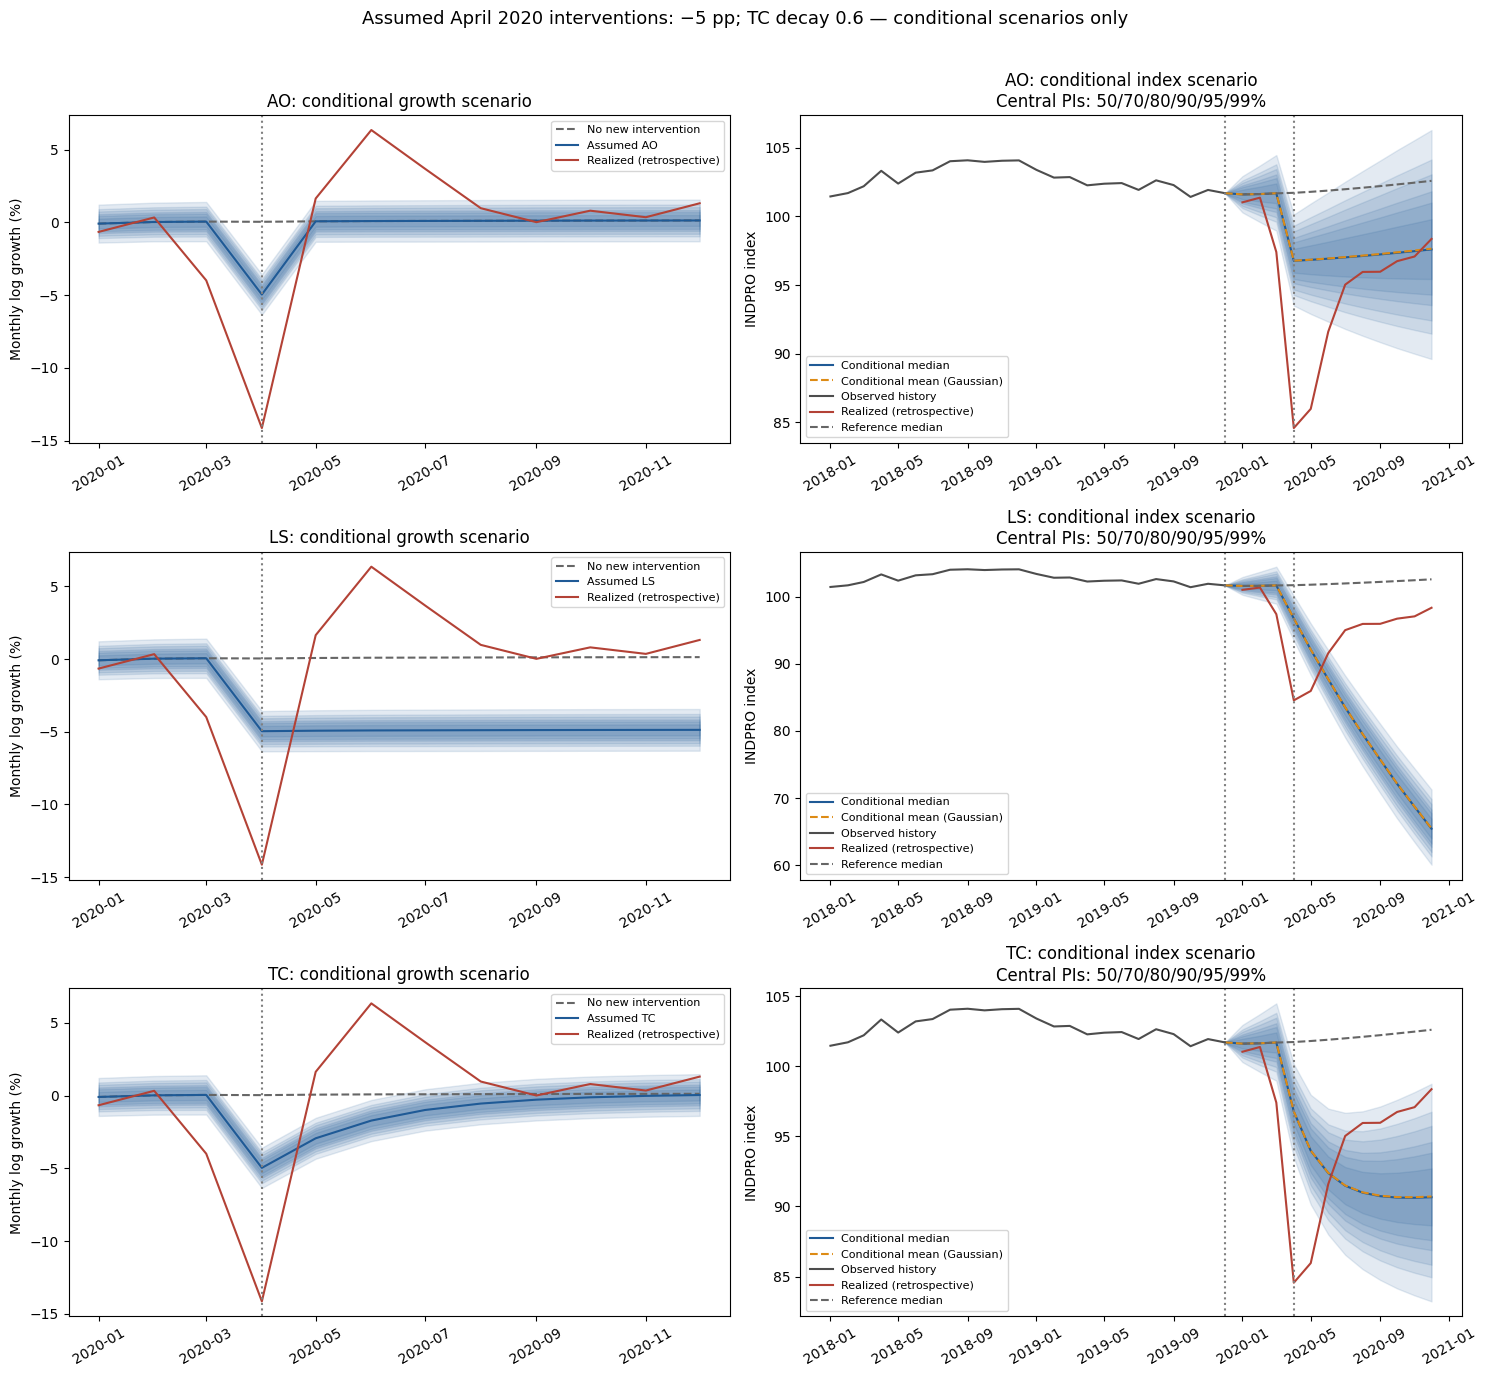

All forecast-date, exogenous alignment, covariance and scenario checks passed.


In [10]:
EVENT_DATE = pd.Timestamp("2020-04-01")
MAGNITUDE = -5.0  # percentage points of monthly log growth
DELTA = 0.6
profiles = pd.DataFrame(index=future_b)
for kind in ("AO", "LS", "TC"):
    generated = at.outlier_regressors(future_b, dates=[EVENT_DATE], types=kind, delta=DELTA)
    pd.testing.assert_index_equal(generated.index, future_b)
    profiles[kind] = generated.iloc[:, 0]

age = np.arange(h_b) - future_b.get_loc(EVENT_DATE)
expected_profiles = {
    "AO": (age == 0).astype(float),
    "LS": (age >= 0).astype(float),
    "TC": np.where(age >= 0, DELTA**np.maximum(age, 0), 0.0),
}
for kind in profiles:
    np.testing.assert_allclose(profiles[kind], expected_profiles[kind])
assert (future_aos_b.to_numpy() == 0).all()
reference_growth = forecast_b_ao
reference_levels = level_tables["B historical AOs"]
scenario_growth, scenario_levels = {}, {}
scenario_summary = []
for kind in profiles:
    shift = MAGNITUDE * profiles[kind]
    table = reference_growth.copy()
    for column in ("Forecast", "Lower", "Upper"):
        table[column] = table[column] + shift
    scenario_growth[kind] = table
    levels, cov, cumulative = level_forecast(ao19, table, float(indpro.loc["2019-12-01"]))
    scenario_levels[kind] = levels
    np.testing.assert_allclose(table.FEV, reference_growth.FEV)
    np.testing.assert_allclose(levels.log_variance, reference_levels.log_variance)
    np.testing.assert_allclose(table.Forecast.loc[:"2020-03"], reference_growth.Forecast.loc[:"2020-03"])
    np.testing.assert_allclose(levels.Median/reference_levels.Median, np.exp(shift.cumsum()/100))
    np.testing.assert_allclose(levels.Mean/reference_levels.Mean, np.exp(shift.cumsum()/100))
    scenario_summary.append({"Scenario": kind,
        "April growth effect (pp)": shift.loc[EVENT_DATE],
        "December growth effect (pp)": shift.iloc[-1],
        "December cumulative log-growth effect (pp)": shift.sum(),
        "December index effect (%)": 100*np.expm1(shift.sum()/100),
        "December median index": levels.Median.iloc[-1],
        "December mean index": levels.Mean.iloc[-1]})

display((MAGNITUDE*profiles).rename_axis("Assumed growth effects (pp)"))
display(pd.DataFrame(scenario_summary).set_index("Scenario").round(5))

fig, axes = plt.subplots(3, 2, figsize=(15, 14))
for row, kind in enumerate(profiles):
    ax = axes[row, 0]
    table = scenario_growth[kind]
    for coverage in reversed(LEVELS):
        z = norm.ppf((1+coverage)/2)
        ax.fill_between(future_b, table.Forecast-z*table.SE, table.Forecast+z*table.SE,
                        color="#1f5a96", alpha=0.12)
    ax.plot(future_b, reference_growth.Forecast, color="0.4", linestyle="--", label="No new intervention")
    ax.plot(future_b, table.Forecast, color="#1f5a96", label=f"Assumed {kind}")
    ax.plot(future_b, growth.reindex(future_b), color="#b34236", label="Realized (retrospective)")
    ax.axvline(EVENT_DATE, color="0.5", linestyle=":")
    ax.set(title=f"{kind}: conditional growth scenario", ylabel="Monthly log growth (%)")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelrotation=30)
    ax = axes[row, 1]
    level_fan(ax, scenario_levels[kind], f"{kind}: conditional index scenario",
              pd.Timestamp("2019-12-01"), float(indpro.loc["2019-12-01"]))
    ax.plot(future_b, reference_levels.Median, color="0.4", linestyle="--", label="Reference median")
    ax.axvline(EVENT_DATE, color="0.5", linestyle=":")
    ax.legend(fontsize=8)
fig.suptitle("Assumed April 2020 interventions: −5 pp; TC decay 0.6 — conditional scenarios only", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()
print("All forecast-date, exogenous alignment, covariance and scenario checks passed.")


### Student questions

1. Why do models with different historical AO treatment forecast differently when future historical AO values are zero?
2. What information is available at each forecast origin?
3. Why do 95% conditional intervals not guarantee coverage during an unforeseen shock?
4. Why do conditional median and mean index forecasts differ? What assumption makes the mean formula exact?
5. Why must cross-horizon covariance enter index uncertainty?
6. Why does an AO in growth leave a persistent index effect, whereas an LS in growth keeps accumulating?
7. Why is a retrospective assumed scenario neither an ex ante event forecast nor a causal estimate?


## 8. Conclusions and next steps

Lab12 constructs dynamic growth and index forecasts, with six central prediction intervals and explicitly assumed intervention scenarios. Lab13 will cover sequential static forecasts, accuracy measures, diagnostics and formal comparisons with Forecasting-Tools.

**Validation scope.** The notebook asserts v1.0.1, monthly forecast indexing, historical-exogenous alignment, estimation convergence, covariance positive semidefiniteness, agreement of ARMA marginal variances with ARIMA-Tools, and scenario/index identities. It reports the full-covariance cumulative variance beside the incorrect sum of marginal variances. Native package fan charts are checked against package numerical intervals before plotting.

**Limits.** These are Gaussian, fixed-parameter, pointwise conditional intervals. They do not incorporate parameter estimation, uncertain intervention assumptions, data revisions or structural breaks. The FRED series is a current revised vintage, not the information vintage available at the forecast origins. Local execution does not replace a fresh Colab smoke test. No package code or Lab11 notebooks are changed.
